# Flight Prices: Dataset Exploration

**Project:** When should you buy a plane ticket? Predicting U.S. domestic flight prices and price drops.\
**Course:** Intro to Machine Learning, Fall 2026\
**Author:** Anita Roese

This notebook explores the [Flight Prices dataset on Kaggle](https://www.kaggle.com/datasets/dilwong/flightprices) (`itineraries.csv`, ~31 GB) and produces every number used in the *Dataset Description* section of the project proposal.

**Approach.** The file is larger than a laptop's memory, so:
- **DuckDB** is used once, only to **count** rows and flights in the full file (it can scan a file without loading it into memory);
- **pandas** is used for everything else, on a reproducible **1% random sample**.

> **Note:** The data is **not** in this repository. Download `itineraries.csv` from Kaggle and place it in the same folder as this notebook.

## 1. Setup

Install DuckDB (only needed the first time), then import the libraries.

In [1]:
%pip install duckdb

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

All settings are defined in one place, so the notebook runs on another machine by changing only `path`.

In [3]:
path = "itineraries.csv"   # change this if the file is somewhere else

CHUNK_SIZE = 1_000_000     # rows pandas reads into memory at a time
SAMPLE_FRAC = 0.01         # keep 1% of rows for analysis
RANDOM_STATE = 42          # makes the sample reproducible

os.makedirs("figures", exist_ok=True)

## 2. Size of the full dataset (DuckDB)

pandas would need to load all 31 GB into memory to count the rows. DuckDB scans the file directly from disk, so it can count every row and every unique flight (`legId`) on a normal laptop.

In [4]:
duckdb.sql(f"""
    SELECT COUNT(*)                 AS rows,
           COUNT(DISTINCT legId)    AS flights,
           MIN(searchDate)          AS first_search,
           MAX(searchDate)          AS last_search,
           COUNT(DISTINCT startingAirport) AS airports
    FROM '{path}'
""").show()

duckdb.sql(f"SELECT DISTINCT startingAirport FROM '{path}' ORDER BY 1").show()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌──────────┬─────────┬──────────────┬─────────────┬──────────┐
│   rows   │ flights │ first_search │ last_search │ airports │
│  int64   │  int64  │     date     │    date     │  int64   │
├──────────┼─────────┼──────────────┼─────────────┼──────────┤
│ 82138753 │ 5999739 │ 2022-04-16   │ 2022-10-05  │       16 │
└──────────┴─────────┴──────────────┴─────────────┴──────────┘



FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

┌─────────────────┐
│ startingAirport │
│     varchar     │
├─────────────────┤
│ ATL             │
│ BOS             │
│ CLT             │
│ DEN             │
│ DFW             │
│ DTW             │
│ EWR             │
│ IAD             │
│ JFK             │
│ LAX             │
│ LGA             │
│ MIA             │
│ OAK             │
│ ORD             │
│ PHL             │
│ SFO             │
└─────────────────┘
      16 rows    



**Interpretation.**
- The dataset has **82,138,753 rows** but only **5,999,739 unique itineraries** (`legId`).
- So each itinerary is observed on about **82.1M ÷ 6.0M ≈ 13.7 search dates** on average. This is what lets us follow how one flight's price changes as departure gets closer.
- Prices were collected between **2022-04-16 and 2022-10-05**, from **16 major U.S. airports**.

**Data leakage:** because the same flight appears ~14 times, a random train/test split would put rows of the same flight in both sets, and the model would be tested on flights it has already seen. The split will therefore be time-based: earlier search dates for training, later ones for testing, with a 7-day gap.

## 3. Columns

Read only the first 5 rows to see the columns without loading the whole file.

In [5]:
preview = pd.read_csv(path, nrows=5)

In [6]:
preview

,legId,searchDate,flightDate,startingAirport,destinationAirport,fareBasisCode,travelDuration,elapsedDays,isBasicEconomy,isRefundable,isNonStop,baseFare,totalFare,seatsRemaining,totalTravelDistance,segmentsDepartureTimeEpochSeconds,segmentsDepartureTimeRaw,segmentsArrivalTimeEpochSeconds,segmentsArrivalTimeRaw,segmentsArrivalAirportCode,segmentsDepartureAirportCode,segmentsAirlineName,segmentsAirlineCode,segmentsEquipmentDescription,segmentsDurationInSeconds,segmentsDistance,segmentsCabinCode
0,9ca0e81111c683bec1012473feefd28f,2022-04-16,2022-04-17,ATL,BOS,LA0NX0MC,PT2H29M,0,False,False,True,217.67,248.6,9,947,1650214620,2022-04-17T12:57:00.000-04:00,1650223560,2022-04-17T15:26:00.000-04:00,BOS,ATL,Delta,DL,Airbus A321,8940,947,coach
1,98685953630e772a098941b71906592b,2022-04-16,2022-04-17,ATL,BOS,LA0NX0MC,PT2H30M,0,False,False,True,217.67,248.6,4,947,1650191400,2022-04-17T06:30:00.000-04:00,1650200400,2022-04-17T09:00:00.000-04:00,BOS,ATL,Delta,DL,Airbus A321,9000,947,coach
2,98d90cbc32bfbb05c2fc32897c7c1087,2022-04-16,2022-04-17,ATL,BOS,LA0NX0MC,PT2H30M,0,False,False,True,217.67,248.6,9,947,1650209700,2022-04-17T11:35:00.000-04:00,1650218700,2022-04-17T14:05:00.000-04:00,BOS,ATL,Delta,DL,Boeing 757-200,9000,947,coach
3,969a269d38eae583f455486fa90877b4,2022-04-16,2022-04-17,ATL,BOS,LA0NX0MC,PT2H32M,0,False,False,True,217.67,248.6,8,947,1650218340,2022-04-17T13:59:00.000-04:00,1650227460,2022-04-17T16:31:00.000-04:00,BOS,ATL,Delta,DL,Airbus A321,9120,947,coach
4,980370cf27c89b40d2833a1d5afc9751,2022-04-16,2022-04-17,ATL,BOS,LA0NX0MC,PT2H34M,0,False,False,True,217.67,248.6,9,947,1650203940,2022-04-17T09:59:00.000-04:00,1650213180,2022-04-17T12:33:00.000-04:00,BOS,ATL,Delta,DL,Airbus A321,9240,947,coach


The file has **27 columns**. Many start with `segments...`: they describe each individual leg of a trip with connections (times, airline, aircraft, cabin), stored as text separated by `||`. This project works at the level of the whole trip, so only the trip-level columns below are used.

In [7]:
cols = ["legId", "searchDate", "flightDate", "startingAirport",
        "destinationAirport", "totalFare", "seatsRemaining",
        "travelDuration", "totalTravelDistance", "isNonStop",
        "isBasicEconomy"]

print(preview.columns.tolist())
preview[cols]

['legId', 'searchDate', 'flightDate', 'startingAirport', 'destinationAirport', 'fareBasisCode', 'travelDuration', 'elapsedDays', 'isBasicEconomy', 'isRefundable', 'isNonStop', 'baseFare', 'totalFare', 'seatsRemaining', 'totalTravelDistance', 'segmentsDepartureTimeEpochSeconds', 'segmentsDepartureTimeRaw', 'segmentsArrivalTimeEpochSeconds', 'segmentsArrivalTimeRaw', 'segmentsArrivalAirportCode', 'segmentsDepartureAirportCode', 'segmentsAirlineName', 'segmentsAirlineCode', 'segmentsEquipmentDescription', 'segmentsDurationInSeconds', 'segmentsDistance', 'segmentsCabinCode']


,legId,searchDate,flightDate,startingAirport,destinationAirport,totalFare,seatsRemaining,travelDuration,totalTravelDistance,isNonStop,isBasicEconomy
0,9ca0e81111c683bec1012473feefd28f,2022-04-16,2022-04-17,ATL,BOS,248.6,9,PT2H29M,947,True,False
1,98685953630e772a098941b71906592b,2022-04-16,2022-04-17,ATL,BOS,248.6,4,PT2H30M,947,True,False
2,98d90cbc32bfbb05c2fc32897c7c1087,2022-04-16,2022-04-17,ATL,BOS,248.6,9,PT2H30M,947,True,False
3,969a269d38eae583f455486fa90877b4,2022-04-16,2022-04-17,ATL,BOS,248.6,8,PT2H32M,947,True,False
4,980370cf27c89b40d2833a1d5afc9751,2022-04-16,2022-04-17,ATL,BOS,248.6,9,PT2H34M,947,True,False


| Column | Meaning |
|---|---|
| `legId` | Unique ID of a flight itinerary |
| `searchDate` | Date the price was observed on Expedia |
| `flightDate` | Date of departure |
| `startingAirport`, `destinationAirport` | Airport codes (16 airports) |
| `totalFare` | **Target:** ticket price in USD, taxes included |
| `seatsRemaining` | Seats left at that price |
| `travelDuration` | Trip length as text, e.g. `PT2H29M` |
| `totalTravelDistance` | Distance in miles |
| `isNonStop`, `isBasicEconomy` | True / False |

## 4. Loading a 1% sample with pandas

To analyze the data in pandas without running out of memory, we:

1. read the file **in chunks** of 1 million rows, keeping only the columns above,
2. keep a **random 1% of each chunk**.

Sampling from every chunk (not just the first rows of the file) keeps the sample spread across all dates and routes.

This cell goes through the whole file once and takes a while. It saves the sample to `sample_1pct.csv`, so next time you can skip it and run the cell after it instead.

In [8]:
if os.path.exists('sample_1pct.csv'):
    df = pd.read_csv('sample_1pct.csv')
else:
    samples = []
    for chunk in pd.read_csv(path, usecols=cols, chunksize=CHUNK_SIZE):
        samples.append(chunk.sample(frac=SAMPLE_FRAC, random_state=RANDOM_STATE))
    
    df = pd.concat(samples, ignore_index=True)
    df.to_csv("sample_1pct.csv", index=False)

print(f"Rows in 1% sample: {len(df):,}")

Rows in 1% sample: 821,388


## 5. Structure and missing values

In [9]:
df.dtypes

legId                      str
searchDate                 str
flightDate                 str
startingAirport            str
destinationAirport         str
travelDuration             str
isBasicEconomy            bool
isNonStop                 bool
totalFare              float64
seatsRemaining           int64
totalTravelDistance    float64
dtype: object

In [10]:
missing_pct = (df.isna().mean() * 100).round(2)
missing_pct[missing_pct > 0]

totalTravelDistance    7.43
dtype: float64

*Interpretation:* Only one selected column has missing values in the 1% sample
(821,388 rows): `totalTravelDistance` is missing for **7.43%** of rows. All other
selected columns are complete. Before modeling, these rows must be handled, either by
dropping them or by filling the distance from other rows of the same route
(`startingAirport` → `destinationAirport`), since distance is nearly fixed per route.
This check covers only the sampled rows and the 11 selected columns.

## 6. Feature engineering

### 6.1 Days until departure

The raw data has two dates but not the variable this project needs most: **how many days before the flight the price was observed**. We create it:

$$\text{daysUntilDeparture} = \text{flightDate} - \text{searchDate}$$

This feature is **engineered**: it is not in the original dataset.

In [11]:
df["searchDate"] = pd.to_datetime(df["searchDate"])
df["flightDate"] = pd.to_datetime(df["flightDate"])
df["daysUntilDeparture"] = (df["flightDate"] - df["searchDate"]).dt.days

df["daysUntilDeparture"].describe()

count    821388.000000
mean         26.903675
std          16.324063
min           1.000000
25%          13.000000
50%          26.000000
75%          40.000000
max          60.000000
Name: daysUntilDeparture, dtype: float64

### 6.2 Travel duration in minutes

`travelDuration` is text in ISO 8601 format (`PT2H29M` = 2 hours 29 minutes; trips longer than a day include days, e.g. `P1DT2H30M`). Models need numbers, so we convert it to minutes, counting days, hours, and minutes.

In [12]:
days  = df["travelDuration"].str.extract(r"(\d+)D")[0].astype(float).fillna(0)
hours = df["travelDuration"].str.extract(r"(\d+)H")[0].astype(float).fillna(0)
mins  = df["travelDuration"].str.extract(r"(\d+)M")[0].astype(float).fillna(0)
df["travelMinutes"] = days * 1440 + hours * 60 + mins

df[["travelDuration", "travelMinutes"]].sort_values("travelMinutes").drop_duplicates().iloc[[0, 1, -2, -1]]

,travelDuration,travelMinutes
61413,PT46M,46.0
30468,PT48M,48.0
145244,P1DT13H40M,2260.0
145463,P1DT14H,2280.0


## 7. Feature summary

These ranges fill the *Example / Range* column of the feature table in the proposal.

In [13]:
numeric_cols = ["daysUntilDeparture", "seatsRemaining", "totalTravelDistance",
                "travelMinutes", "totalFare"]
df[numeric_cols].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
daysUntilDeparture,821388.0,26.90,16.32,1.00,13.0,26.00,40.0,60.0
seatsRemaining,821388.0,5.98,2.88,0.00,4.0,7.00,9.0,10.0
totalTravelDistance,760389.0,1609.33,857.10,89.00,876.0,1468.00,2415.0,4654.0
travelMinutes,821388.0,428.18,225.32,46.00,262.0,409.00,566.0,2280.0
totalFare,821388.0,340.38,195.57,19.59,197.2,305.61,452.2,4913.6


In [14]:
for col in ["isNonStop", "isBasicEconomy"]:
    print(f"{col}: {df[col].mean():.1%} True")

isNonStop: 26.9% True
isBasicEconomy: 14.4% True


## 8. Target variable: `totalFare`

This is a **regression** task, so the target is described by its mean, median, standard deviation, range, and skew.

- **Skew ≈ 0** → roughly symmetric
- **Skew > 1** → strongly right-skewed (most tickets are cheap, a few are very expensive)

In [15]:
fare = df["totalFare"]
print(f"Mean:    ${fare.mean():,.2f}")
print(f"Median:  ${fare.median():,.2f}")
print(f"Std dev: ${fare.std():,.2f}")
print(f"Min:     ${fare.min():,.2f}")
print(f"Max:     ${fare.max():,.2f}")
print(f"Skew:    {fare.skew():.2f}")

Mean:    $340.38
Median:  $305.61
Std dev: $195.57
Min:     $19.59
Max:     $4,913.60
Skew:    2.02


*Interpretation:* `totalFare` is strongly **right-skewed** (skew = 2.02). The mean
(340.38 USD) is higher than the median (305.61 USD) because a small number of very
expensive tickets (up to 4,913.60 USD) pull the average up, while most fares are much
lower. The standard deviation (195.57 USD) is large relative to the mean, so prices
vary a lot across routes and dates. Because linear regression works best when errors
are roughly symmetric, modeling `log(totalFare)` instead of the raw price may give
better results; the histograms below compare the two.

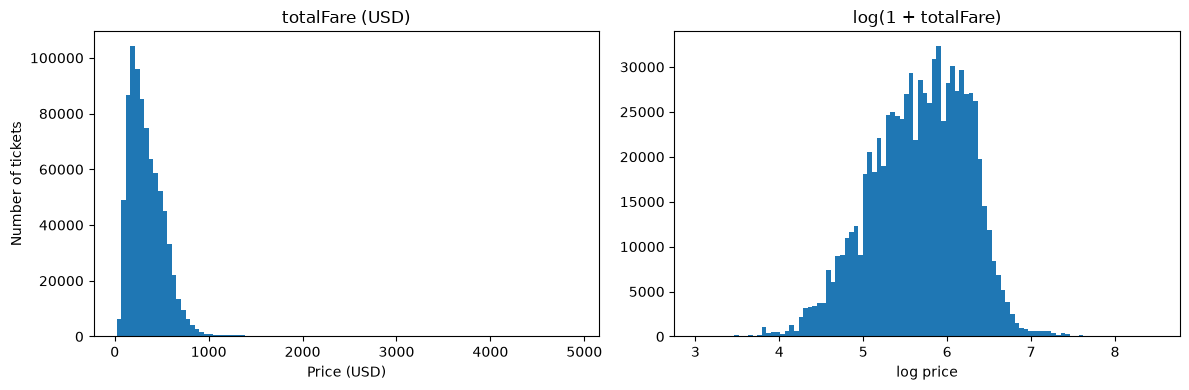

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(fare, bins=100)
axes[0].set_title("totalFare (USD)")
axes[0].set_xlabel("Price (USD)")
axes[0].set_ylabel("Number of tickets")

axes[1].hist(np.log1p(fare), bins=100)
axes[1].set_title("log(1 + totalFare)")
axes[1].set_xlabel("log price")

plt.tight_layout()
plt.savefig("figures/fare_distribution.png", dpi=150)   # reuse as a figure in the proposal
plt.show()

*Interpretation:* The raw fares (left) are concentrated between about 150 and 250 USD,
and nearly all tickets cost less than 1,000 USD, but the x-axis extends to about
5,000 USD because of a small number of very expensive tickets. This long right tail
is what produces the skew of 2.02. After the log transform (right), the distribution
is much closer to symmetric, centered around a log price of about 5.8 (roughly 330 USD),
with only a slightly longer tail toward cheaper fares. The jagged bars reflect that
airlines use common price points, so many tickets share the same fare. Because the
log-transformed target is far more symmetric, log(totalFare) is a better candidate
target for linear regression than the raw price.

### 8.1 Price vs. days until departure

A first look at the research question: does the average price change depending on how far ahead the ticket is bought?

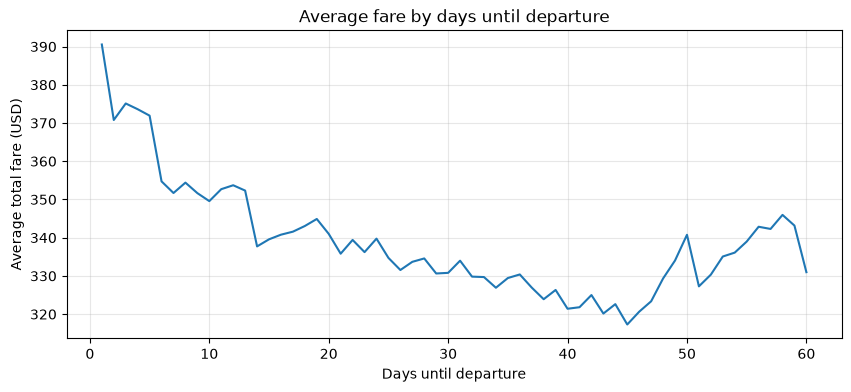

In [17]:
avg_by_day = df.groupby("daysUntilDeparture")["totalFare"].mean()

plt.figure(figsize=(10, 4))
plt.plot(avg_by_day.index, avg_by_day.values)
plt.xlabel("Days until departure")
plt.ylabel("Average total fare (USD)")
plt.title("Average fare by days until departure")
plt.grid(alpha=0.3)
plt.savefig("figures/fare_vs_days.png", dpi=150)
plt.show()

*Interpretation:* Average fare is highest for last-minute purchases (about 390 USD one
day before departure) and lowest around 45 days before departure (about 317 USD), a
difference of roughly 73 USD (~20%). Prices fall in visible steps near 7 and 14 days
before departure, consistent with airline advance-purchase rules, then decline gradually
until about 45 days out, after which they rise again. The relationship is therefore
**curved, not linear**: a linear regression using only `daysUntilDeparture` would miss
this shape. Possible fixes that keep the model linear include adding a squared term
(`daysUntilDeparture²`) or grouping days into ranges (e.g., 0–6, 7–13, 14–20, 21+).
Note that these are averages across all routes; part of the pattern may come from
which routes happen to be observed at each lead time, so it shows association, not
cause.

## 9. Key Takeaways and Next Steps

**What the data looks like**
- The full dataset has **82,138,753 rows** and **27 columns** (~31 GB), covering **5,999,739 unique itineraries** from **16 major U.S. airports**, searched between April 16 and October 5, 2022.
- Each itinerary is observed on about **14 search dates** on average, which makes it possible to follow how one flight's price changes over time.
- Prices were observed **1 to 60 days** before departure, spread roughly evenly across that window.

**Data quality**
- `totalTravelDistance` is missing for **7.43%** of rows in the sample; all other selected columns are complete.
- `travelDuration` is stored as text and was converted to minutes (including trips longer than one day).

**Target: `totalFare`**
- Strongly **right-skewed** (skew = 2.02): mean 340.38 USD vs. median 305.61 USD. The log of the fare is much closer to symmetric, so `log(totalFare)` is a candidate target for linear regression.
- Average fare is highest for last-minute purchases (~390 USD one day out) and lowest around **45 days** before departure (~317 USD). The relationship is **curved**, so the model will include a squared term for days until departure.

**Implications for modeling**
- Because the same flight appears many times, the train/test split will be **time-based with a 7-day gap**, to avoid data leakage.
- A random 1% sample keeps too few searches per flight to track price changes, so modeling will use **5–10 selected routes with every search kept**.

**Next:** `02_route_extraction.ipynb` selects the routes, extracts all their searches with DuckDB, and builds the `wait` label (1 if the same flight's price drops within the next 7 days).